# Olist E-Commerce Data Cleaning

This notebook cleans and prepares six source datasets for subsequent SQL analysis and Power BI reporting. The category translation is incorporated into Products, leaving five core cleaned datasets for export. The original workflow is retained: data understanding, cleaning and outlier inspection, row-level feature preparation, and final validation/export. Business aggregation, KPI calculation, and business diagnosis remain in the SQL and BI stages.

**Revision scope:** clarify delivery definitions, preserve an exact elapsed-duration field alongside the existing integer field, identify valid delivery-analysis samples, flag timestamp and review-timing issues, and strengthen final validation. Source observations are retained; flags control eligibility for particular downstream calculations.

**Run locally:** keep this notebook in the project's notebooks folder, with the original CSVs under ../data/raw/. Run cells from top to bottom using a Jupyter Python environment with pandas, NumPy, and Matplotlib. The existing relative input and output paths are unchanged. Five core files are written to ../data/clean/ and one supporting quality report to ../reports/.

**SQL handoff:** existing columns are preserved. Additional columns require a schema/import check before reloading an existing SQL table. The revised is_late eligibility and explicit calendar-date delay definition should be checked against the existing SQL calculations before Power BI work begins.

In [1]:
import os
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 

orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")
reviews = pd.read_csv("../data/raw/olist_order_reviews_dataset.csv")
items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")
products = pd.read_csv("../data/raw/olist_products_dataset.csv")
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")
category_translation = pd.read_csv("../data/raw/product_category_name_translation.csv")

# 1. Data Overview

In [2]:
datasets = {
    "Orders": orders,
    "Order Items": items,
    "Reviews": reviews,
    "Products": products,
    "Customers": customers,
    "Category Translation": category_translation,
}

In [3]:
overview = pd.DataFrame({
    "Dataset": datasets.keys(),
    "Rows": [df.shape[0] for df in datasets.values()],
    "Columns": [df.shape[1] for df in datasets.values()],
    "Missing Values": [df.isnull().sum().sum() for df in datasets.values()],
    "Duplicate Rows": [df.duplicated().sum() for df in datasets.values()]
})

overview

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,Orders,99441,8,4908,0
1,Order Items,112650,7,0,0
2,Reviews,99224,7,145903,0
3,Products,32951,9,2448,0
4,Customers,99441,5,0,0
5,Category Translation,71,2,0,0


In [4]:
for name, df in datasets.items():
    print(" "*100)
    print(f"{name.upper()}")

    print("\nShape:")
    print(df.shape)

    print("\nFirst 10 Rows:")
    display(df.head(10))

    print("\nData Types:")
    display(df.dtypes)

    print("\nMissing Values:")
    display(df.isnull().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())

                                                                                                    
ORDERS

Shape:
(99441, 8)

First 10 Rows:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01 00:00:00
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07 00:00:00
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23 00:00:00



Data Types:


order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object


Missing Values:


order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

... (27 outputs left out)

product_category_name            object
product_category_name_english    object
dtype: object


Missing Values:


product_category_name            0
product_category_name_english    0
dtype: int64


Duplicate Rows:
0


## 1.1 Overall Insights and Data Cleaning Needed

### Initial Insights

- The Orders table is the central table and contains 99,441 unique orders.
- The Order Items table has more rows than unique orders because one order can contain multiple items.
- The Reviews table can also contain multiple review records for the same order and therefore requires further investigation before it is merged at order level.
- `customer_id` links Customers to Orders, while `customer_unique_id` identifies the same customer across different orders. Both fields should be retained.
- Missing review comments are expected because text feedback is optional.
- Product categories, descriptions, and a very small number of physical attributes contain missing values.

### Data Cleaning Needed

- Convert all date strings to datetime.
- Resolve multiple review records at order level.
- Remove review text columns because text analysis is outside the project scope.
- Handle missing values in Orders and Products according to business meaning.
- Merge the English product-category translation into Products.
- Inspect numerical outliers before deciding whether any observations should be removed.

## 1.2 Check Important IDs and Table Grain

In [5]:
for name, df in datasets.items():
    print(" "*100)
    print(f"{name.upper()}")
    display("Rows:", len(df))
    display("Unique values:", df.nunique())

                                                                                                    
ORDERS


'Rows:'

99441

'Unique values:'

order_id                         99441
customer_id                      99441
order_status                         8
order_purchase_timestamp         98875
order_approved_at                90733
order_delivered_carrier_date     81018
order_delivered_customer_date    95664
order_estimated_delivery_date      459
dtype: int64

                                                                                                    
ORDER ITEMS


... (20 outputs left out)

'Rows:'

71

'Unique values:'

product_category_name            71
product_category_name_english    71
dtype: int64

- Each `order_id` in Orders and each `customer_id` in Customers is unique.
- `customer_unique_id` has fewer unique values than `customer_id`, showing that some shoppers placed more than one order.
- The Orders table contains eight order statuses.
- Order Items contains multiple rows for some orders because each row represents one item in an order.
- Some order IDs appear in Orders but not in Order Items; these may represent cancelled or unavailable orders.
- Reviews use a 1–5 rating system. The difference between the number of unique `review_id` and `order_id` values requires further investigation.

### Orders and Order Items Relationship

In [6]:
orders_without_items = orders[
    ~orders["order_id"].isin(items["order_id"])
]

print("Orders without items:", len(orders_without_items))

Orders without items: 775


In [7]:
orders_without_items["order_status"].value_counts()

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

In [8]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [9]:
items_per_order = (
    items
    .groupby("order_id")
    .size()
)

items_per_order.describe()

count    98666.000000
mean         1.141731
std          0.538452
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         21.000000
dtype: float64

The 775 orders without item records are concentrated in `unavailable` and `canceled` statuses. They are therefore retained in Orders rather than treated as broken records. Their absence from Order Items reflects order lifecycle status rather than a primary-key error.

### Source Time Coverage

Monthly row counts describe the coverage of this extract, not automatically the health of the business. Sparse boundary months must be inspected before calculating growth or interpreting a decline. Display the first and last observed months below; keep all source rows in the cleaned export. A month with zero orders is also included in this coverage check. The final reporting window and any exclusions will be documented in SQL/BI.

In [10]:
purchase_timestamps_for_coverage = pd.to_datetime(orders["order_purchase_timestamp"])
coverage_start = purchase_timestamps_for_coverage.min().to_period("M")
coverage_end = purchase_timestamps_for_coverage.max().to_period("M")
monthly_order_coverage = (
    purchase_timestamps_for_coverage.dt.to_period("M")
    .value_counts()
    .sort_index()
    .reindex(pd.period_range(coverage_start, coverage_end, freq="M"), fill_value=0)
    .rename_axis("Purchase Month")
    .rename("Order Count")
    .to_frame()
)
print("Purchase timestamp range:", purchase_timestamps_for_coverage.min(),
      "to", purchase_timestamps_for_coverage.max())
display(pd.concat([
    monthly_order_coverage.head(4), monthly_order_coverage.tail(4)
]).loc[lambda frame: ~frame.index.duplicated()])

Purchase timestamp range: 2016-09-04 21:15:19 to 2018-10-17 17:30:18


,Order Count
Purchase Month,
2016-09,4
2016-10,324
2016-11,0
2016-12,1
2018-07,6292
2018-08,6512
2018-09,16
2018-10,4


### Multiple Review Records per Order

In [11]:
print(
    "Duplicate review_id + order_id pairs:",
    reviews.duplicated(
        subset=["review_id", "order_id"]
    ).sum()
)

Duplicate review_id + order_id pairs: 0


In [12]:
reviews_per_order = (
    reviews
    .groupby("order_id")
    .size()
    .sort_values(ascending=False)
)

print(reviews_per_order.value_counts().sort_index())

1    98126
2      543
3        4
Name: count, dtype: int64


In [13]:
multiple_review_orders = reviews_per_order[
    reviews_per_order > 1
]

print("Orders with multiple review rows:",
      len(multiple_review_orders))

display(multiple_review_orders.head(10))

Orders with multiple review rows: 547


order_id
03c939fd7fd3b38f8485a0f95798f1f6    3
c88b1d1b157a9999ce368f218a407141    3
8e17072ec97ce29f0e1f111e598b0c85    3
df56136b8031ecd28e200bb18e6ddb2e    3
075a544c5f4ed4bb75f82b160465fe76    2
823384842bb58973b0c88e31c6f94da9    2
d61b915b69851aec8a8865f36cfd793e    2
8e350e1e4254bd7c68913b98bde7d3a7    2
7f13a20e25350f4a55fb2a7c9a2e8d88    2
49fd347705840c689965d81ae7f2b415    2
dtype: int64

Check whether multiple reviews for the same order contain different scores.

In [14]:
scores_per_order = (
    reviews
    .groupby("order_id")["review_score"]
    .nunique()
)

scores_per_order.value_counts().sort_index()

review_score
1    98471
2      202
Name: count, dtype: int64

In [15]:
multiple_reviews = reviews[
    reviews["order_id"].isin(
        multiple_review_orders.index
    )
].sort_values("order_id")

display(
    multiple_reviews[
        [
            "order_id",
            "review_id",
            "review_score",
            "review_creation_date",
            "review_answer_timestamp"
        ]
    ].head(30)
)

,order_id,review_id,review_score,review_creation_date,review_answer_timestamp
25612,0035246a40f520710769010f752e7507,89a02c45c340aeeb1354a24e7d4b2c1e,5,2017-08-29 00:00:00,2017-08-30 01:59:12
22423,0035246a40f520710769010f752e7507,2a74b0559eb58fc1ff842ecc999594cb,5,2017-08-25 00:00:00,2017-08-29 21:45:57
22779,013056cfe49763c6f66bda03396c5ee3,ab30810c29da5da8045216f0f62652a2,5,2018-02-22 00:00:00,2018-02-23 12:12:30
68633,013056cfe49763c6f66bda03396c5ee3,73413b847f63e02bc752b364f6d05ee9,4,2018-03-04 00:00:00,2018-03-05 17:02:00
854,0176a6846bcb3b0d3aa3116a9a768597,830636803620cdf8b6ffaf1b2f6e92b2,5,2017-12-30 00:00:00,2018-01-02 10:54:06
83224,0176a6846bcb3b0d3aa3116a9a768597,d8e8c42271c8fb67b9dad95d98c8ff80,5,2017-12-30 00:00:00,2018-01-02 10:54:47
17582,02355020fd0a40a0d56df9f6ff060413,017f0e1ea6386de662cbeba299c59ad1,1,2018-03-29 00:00:00,2018-03-30 03:16:19
89888,02355020fd0a40a0d56df9f6ff060413,0c8e7347f1cdd2aede37371543e3d163,3,2018-03-21 00:00:00,2018-03-22 01:32:08
55137,029863af4b968de1e5d6a82782e662f5,61fe4e7d1ae801bbe169eb67b86c6eda,4,2017-07-19 00:00:00,2017-07-20 12:06:11
37911,029863af4b968de1e5d6a82782e662f5,04d945e95c788a3aa1ffbee42105637b,5,2017-07-14 00:00:00,2017-07-17 13:58:06


- The Review dataset contains 99,224 rows covering 98,673 unique orders.
- 98,126 orders have one review record, 543 have two, and 4 have three.
- 202 orders contain conflicting review scores.
- `(review_id, order_id)` uniquely identifies each review record.
- Since the final analysis uses orders as the main unit of observation, multiple review records must be resolved before joining Reviews to Orders.
- For each order, retain the record with the latest review_creation_date, breaking ties by review_answer_timestamp. This preserves the agreed one-review-per-order policy. It selects the latest created review record, which is not necessarily the last response chronologically and should not be assumed to be a post-delivery assessment. Section 3.3 flags review responses recorded before customer delivery.

In [16]:
reviews["review_creation_date"] = pd.to_datetime(
    reviews["review_creation_date"]
)

reviews["review_answer_timestamp"] = pd.to_datetime(
    reviews["review_answer_timestamp"]
)

In [17]:
reviews_sorted = reviews.sort_values(
    ["order_id", "review_creation_date", "review_answer_timestamp"]
)

In [18]:
reviews_latest = (
    reviews_sorted
    .drop_duplicates(
        subset="order_id",
        keep="last"
    )
    .copy()
)

In [19]:
print("Rows:", len(reviews_latest))

print(
    "Unique orders:",
    reviews_latest["order_id"].nunique()
)

Rows: 98673
Unique orders: 98673


## 1.3 Numerical and Categorical Distribution Summary

In [20]:
for name, df in datasets.items():
    print(f"\n{name}")
    display(df.describe())


Orders


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-02-19 15:37:47,2018-02-27 04:31:10,2018-05-09 15:48:00,2016-10-27 17:32:07,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522



Order Items


,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000



Reviews


,review_score,review_creation_date,review_answer_timestamp
count,99224.000000,99224,99224
mean,4.086421,2018-01-12 20:49:23.948238336,2018-01-16 00:23:56.977938688
min,1.000000,2016-10-02 00:00:00,2016-10-07 18:32:28
25%,4.000000,2017-09-23 00:00:00,2017-09-27 01:53:27.249999872
50%,5.000000,2018-02-02 00:00:00,2018-02-04 22:41:47.500000
75%,5.000000,2018-05-16 00:00:00,2018-05-20 12:11:21.500000
max,5.000000,2018-08-31 00:00:00,2018-10-29 12:27:35
std,1.347579,NaN,NaN


... (2 outputs left out)


Customers


,customer_zip_code_prefix
count,99441.000000
mean,35137.474583
std,29797.938996
min,1003.000000
25%,11347.000000
50%,24416.000000
75%,58900.000000
max,99990.000000



Category Translation


,product_category_name,product_category_name_english
count,71,71
unique,71,71
top,beleza_saude,health_beauty
freq,1,1


In [21]:
for name, df in datasets.items():
    print(f"\n{name}")
    display(df.describe(include="object"))


Orders


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-02-19 15:37:47,2018-02-27 04:31:10,2018-05-09 15:48:00,2016-10-27 17:32:07,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522



Order Items


,order_id,product_id,seller_id,shipping_limit_date
count,112650,112650,112650,112650
unique,98666,32951,3095,93318
top,8272b63d03f5f79c56e9e4120aec44ef,aca2eb7d00ea1a7b8ebd4e68314663af,6560211a19b47992c3666cc44a7e94c0,2018-03-01 02:50:48
freq,21,527,2033,21



Reviews


,review_id,order_id,review_comment_title,review_comment_message
count,99224,99224,11568,40977
unique,98410,98673,4527,36159
top,4548534449b1f572e357211b90724f1b,8e17072ec97ce29f0e1f111e598b0c85,Recomendo,Muito bom
freq,3,3,423,230


... (2 outputs left out)


Customers


,customer_id,customer_unique_id,customer_city,customer_state
count,99441,99441,99441,99441
unique,99441,96096,4119,27
top,06b8999e2fba1a1fbc88172c00ba8bc7,8d50f5eadf50201ccdcedfb9e2ac8455,sao paulo,SP
freq,1,17,15540,41746



Category Translation


,product_category_name,product_category_name_english
count,71,71
unique,71,71
top,beleza_saude,health_beauty
freq,1,1


# 2. Data Cleaning and Outlier Inspection

## 2.1 Drop Unnecessary Columns

In [22]:
reviews_latest.drop(
    columns=["review_comment_title", "review_comment_message"],
    inplace=True
)

reviews_latest.head()

,review_id,order_id,review_score,review_creation_date,review_answer_timestamp
51963,97ca439bc427b48bc1cd7177abe71365,00010242fe8c5a6d1ba2dd792cb16214,5,2017-09-21,2017-09-22 10:57:03
27823,7b07bacd811c4117b742569b04ce3580,00018f77f2f0320c557190d7a144bdd3,4,2017-05-13,2017-05-15 11:34:13
4218,0c5b33dea94867d1ac402749e5438e8b,000229ec398224ef6ca0657da4fc703e,5,2018-01-23,2018-01-23 16:06:31
38844,f4028d019cb58564807486a6aaf33817,00024acbcdf0a6daa1e931b038114c75,4,2018-08-15,2018-08-15 16:39:01
55676,940144190dcba6351888cafa43f3a3a5,00042b26cf59d7ce69dfabb4e55b4fd9,5,2017-03-02,2017-03-03 10:54:59


Review titles and comments are removed because they have high missing rates and the current project does not include text analysis. Review score and timestamps are retained for customer-satisfaction analysis.

## 2.2 Fix Data Types and Basic Formatting

In [23]:
order_date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

orders[order_date_cols] = orders[order_date_cols].apply(pd.to_datetime)
items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"])

orders.head()
items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [24]:
review_date_cols = [
    "review_creation_date",
    "review_answer_timestamp"
]

datetime_columns = {
    "Orders": order_date_cols,
    "Order Items": ["shipping_limit_date"],
    "Reviews": review_date_cols
}

datasets_dict = {
    "Orders": orders,
    "Order Items": items,
    "Reviews": reviews_latest
}

for table, cols in datetime_columns.items():
    print(f"\n{table}")
    display(datasets_dict[table][cols].dtypes)


Orders


order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


Order Items


shipping_limit_date    datetime64[ns]
dtype: object


Reviews


review_creation_date       datetime64[ns]
review_answer_timestamp    datetime64[ns]
dtype: object

In [25]:
products.rename(
    columns={
        "product_name_lenght": "product_name_length",
        "product_description_lenght": "product_description_length"
    },
    inplace=True
)

## 2.3 Handle Missing Values

### Missing Order Timestamps

In [26]:
missing_order_date_cols = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

for col in missing_order_date_cols:
    print(f"\n===== {col} =====")

    missing = orders.loc[
        orders[col].isna(),
        "order_status"
    ]

    print("Missing:", len(missing))
    print(missing.value_counts())


===== order_approved_at =====
Missing: 160
order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

===== order_delivered_carrier_date =====
Missing: 1783
order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64

===== order_delivered_customer_date =====
Missing: 2965
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


Missing delivery-related timestamps are largely structural: they mainly correspond to cancelled, unavailable, or incomplete orders. These values are preserved because filling them would create approval, dispatch, or delivery events that may never have occurred.

The small number of missing timestamps among delivered orders is also retained. Those rows can be excluded only when a specific delivery calculation requires the missing field.

### Missing Product Attributes

In [27]:
display(products.isnull().sum())

missing_category_products = products[
    products["product_category_name"].isna()
]

duplicate_products = missing_category_products[
    "product_id"
].duplicated().sum()

print(f"Duplicate product_ids among missing categories: {duplicate_products}")

display(missing_category_products.isnull().sum())

product_id                      0
product_category_name         610
product_name_length           610
product_description_length    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Duplicate product_ids among missing categories: 0


product_id                      0
product_category_name         610
product_name_length           610
product_description_length    610
product_photos_qty            610
product_weight_g                1
product_length_cm               1
product_height_cm               1
product_width_cm                1
dtype: int64

In [28]:
products["product_category_name"] = products[
    "product_category_name"
].fillna("unknown")

physical_cols = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

products["missing_physical_attributes"] = (
    products[physical_cols]
    .isna()
    .any(axis=1)
    .astype("int8")
)

print(
    "Products with missing physical attributes:",
    products["missing_physical_attributes"].sum()
)

Products with missing physical attributes: 2


- The 610 products with missing categories also lack name length, description length, and photo quantity. Their category is labelled `unknown`, while the other descriptive fields remain missing.
- Only two products have missing physical attributes. These values are preserved and flagged rather than estimated because median imputation would create artificial product specifications.
- Missing review text no longer requires treatment because the two free-text columns were removed.

## 2.4 Translate Product Categories

In [29]:
products = products.merge(
    category_translation,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

products["product_category_name_english"] = (
    products["product_category_name_english"]
    .fillna(products["product_category_name"])
)

print(
    "Products without an English category:",
    products["product_category_name_english"].isna().sum()
)

products.head()

Products without an English category: 0


,product_id,product_category_name,product_name_length,product_description_length,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,missing_physical_attributes,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,0,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,0,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,0,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,0,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,0,housewares


The translation table is merged into Products so that downstream SQL and BI analysis can use readable English category names. Where no official translation exists, the original category value is retained. The standalone translation table therefore does not need to be exported separately.

## 2.5 Inspect Numerical Distributions and Outliers


ORDER ITEMS


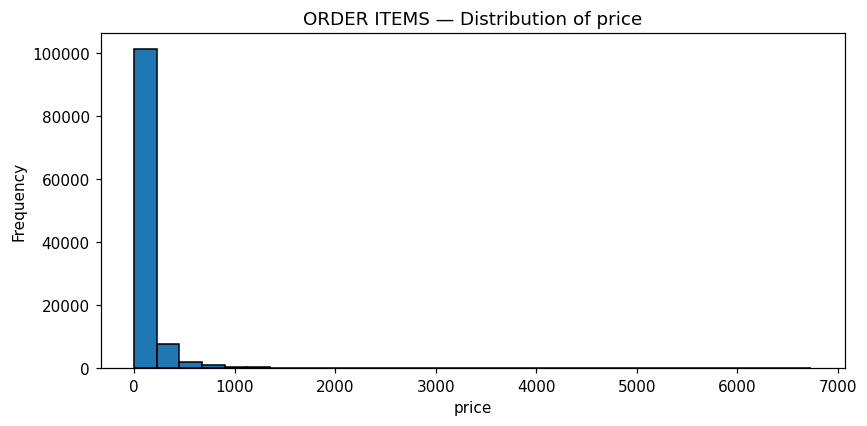

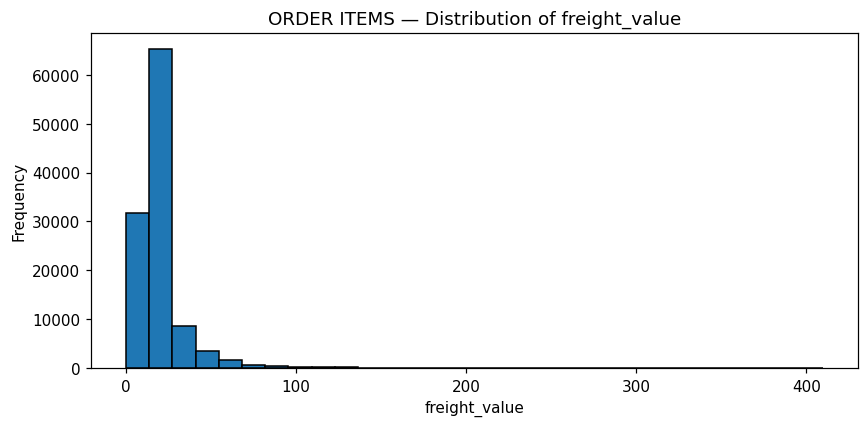


PRODUCTS


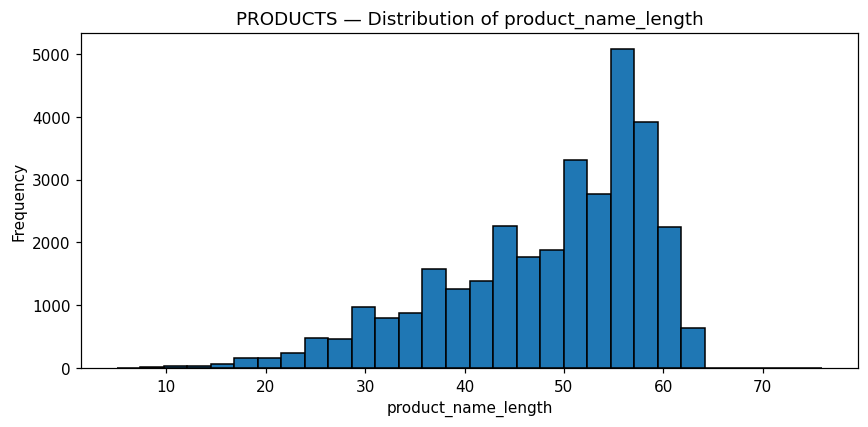

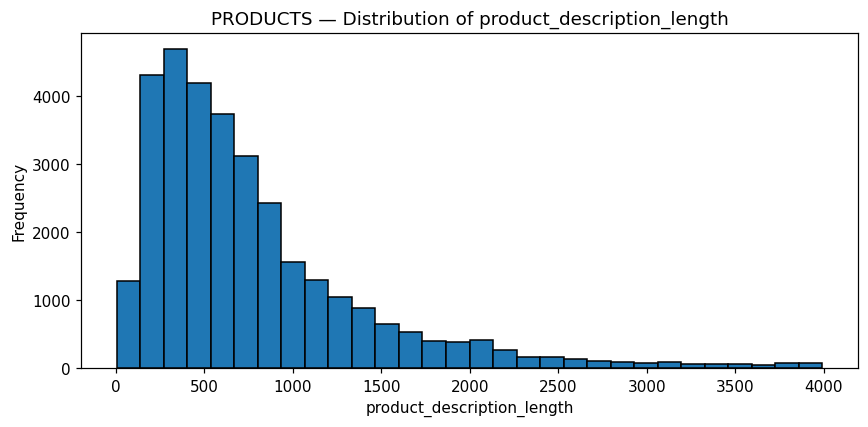

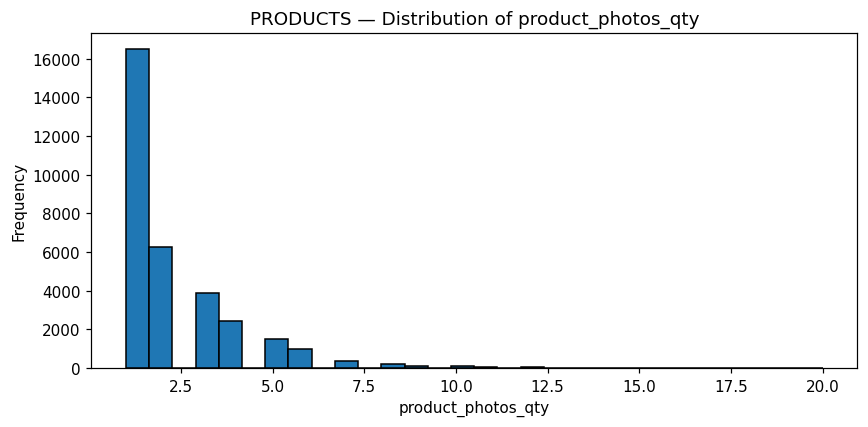

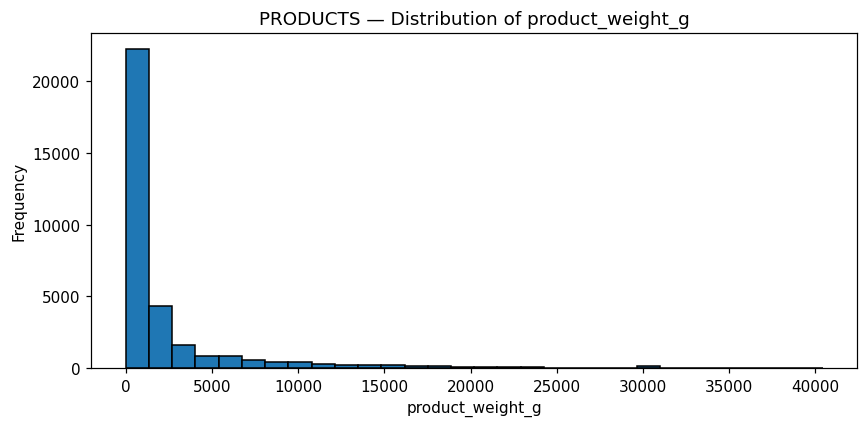

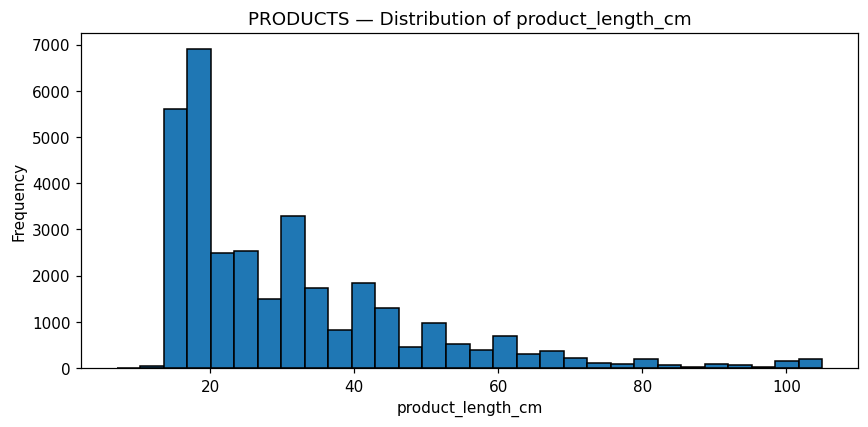

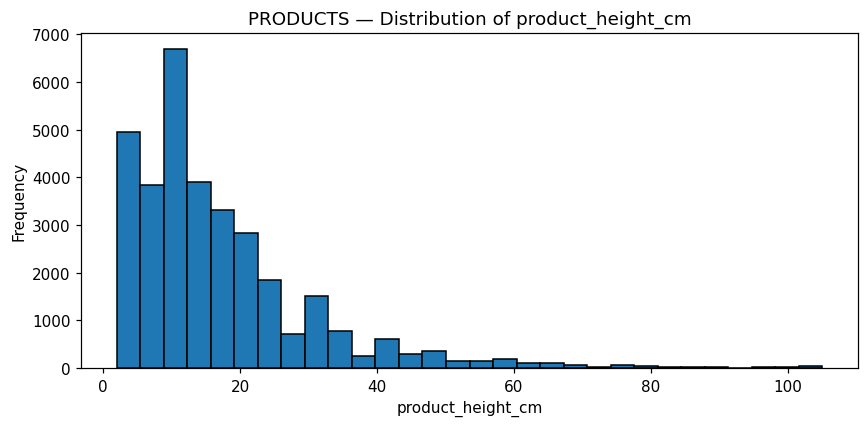

In [30]:
distribution_tables = {
    "Order Items": items,
    "Products": products
}

for name, df in distribution_tables.items():

    print(f"\n{name.upper()}")

    numerical_cols = df.select_dtypes(include="number").columns

    for col in numerical_cols:

        # Skip ID/code-like and flag columns
        if (
            "id" in col.lower()
            or "zip_code" in col.lower()
            or col == "missing_physical_attributes"
        ):
            continue

        plt.figure(figsize=(8, 4))

        plt.hist(
            df[col].dropna(),
            bins=30,
            edgecolor="black"
        )

        plt.title(f"{name.upper()} — Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")

        plt.tight_layout()
        plt.show()

### Price and Freight Value

In [31]:
def iqr_summary(df, column):
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr
    outliers = df[df[column] > upper_bound]

    return pd.Series({
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Upper Bound": upper_bound,
        "Outliers": len(outliers),
        "Outlier Percentage": len(outliers) / len(df) * 100
    })

display(iqr_summary(items, "price"))
display(iqr_summary(items, "freight_value"))

Q1                      39.900000
Q3                     134.900000
IQR                     95.000000
Upper Bound            277.400000
Outliers              8427.000000
Outlier Percentage       7.480692
dtype: float64

Q1                       13.080000
Q3                       21.150000
IQR                       8.070000
Upper Bound              33.255000
Outliers              11613.000000
Outlier Percentage       10.308921
dtype: float64

Price–freight correlation: 0.414


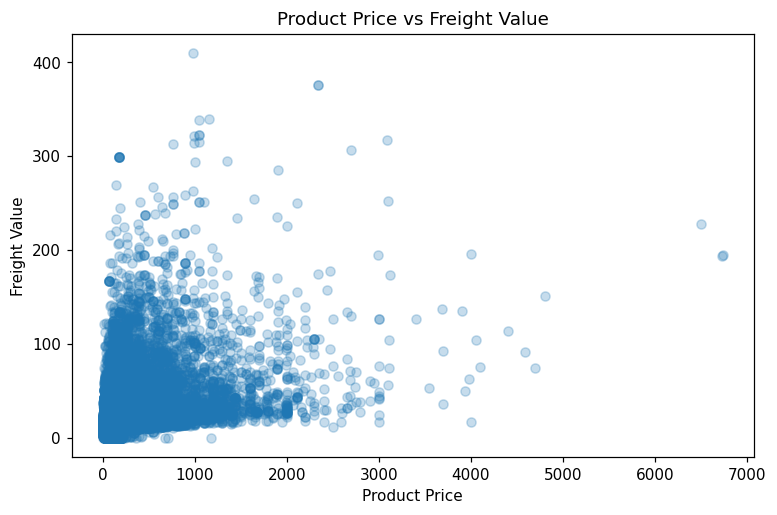

In [32]:
price_freight_correlation = items["price"].corr(
    items["freight_value"]
)

print(f"Price–freight correlation: {price_freight_correlation:.3f}")

plt.figure(figsize=(8, 5))
plt.scatter(
    items["price"],
    items["freight_value"],
    alpha=0.25
)
plt.xlabel("Product Price")
plt.ylabel("Freight Value")
plt.title("Product Price vs Freight Value")
plt.show()

Product price and freight value show a moderate positive relationship: more expensive products tend to have higher freight charges, although price alone does not determine shipping cost. Product weight, dimensions, and shipping distance can also influence freight value. The high-value observations remain commercially plausible, so the statistical outliers are retained rather than treated as data-quality errors.

Correlation describes the overall relationship and does not verify every individual extreme observation. No high-value observation is deleted solely because it exceeds the IQR upper threshold; row-level investigation can be added if a downstream result is disproportionately influenced by a particular observation.

### Product Weight and Dimensions

In [33]:
display(iqr_summary(products, "product_weight_g"))

products["product_volume_cm3"] = (
    products["product_length_cm"]
    * products["product_height_cm"]
    * products["product_width_cm"]
)

display(
    products[["product_weight_g", "product_volume_cm3"]]
    .corr()
)

Q1                     300.000000
Q3                    1900.000000
IQR                   1600.000000
Upper Bound           4300.000000
Outliers              4551.000000
Outlier Percentage      13.811417
dtype: float64

,product_weight_g,product_volume_cm3
product_weight_g,1.000000,0.803005
product_volume_cm3,0.803005,1.000000


In [34]:
freight = items.merge(
    products[["product_id", "product_weight_g", "product_volume_cm3"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

weight_freight_correlation = freight[
    "product_weight_g"
].corr(freight["freight_value"])

print(
    f"Product weight–freight correlation: "
    f"{weight_freight_correlation:.3f}"
)

Product weight–freight correlation: 0.610


Product weight and volume are positively related, and heavier products generally incur higher freight charges. This supports the interpretation that large product and freight values can reflect real product characteristics. No numerical outliers are removed at this stage.

This is supporting evidence at the population level, rather than proof that every extreme value is correct. Missing physical attributes remain flagged. Zero or otherwise questionable physical measurements should be reviewed before any analysis that specifically depends on product dimensions or weight.

# 3. Basic Feature Preparation

In [35]:
orders["purchase_date"] = orders[
    "order_purchase_timestamp"
].dt.date

orders["purchase_year"] = orders[
    "order_purchase_timestamp"
].dt.year

orders["purchase_month"] = orders[
    "order_purchase_timestamp"
].dt.month

# Preserve the existing field: whole elapsed 24-hour periods, rounded down.
delivery_elapsed = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]
)
orders["delivery_days"] = delivery_elapsed.dt.days.astype("Int64")

# Eligibility for exact purchase-to-delivery duration does not require an estimate.
valid_delivery_duration = (
    orders["order_status"].eq("delivered")
    & orders["order_purchase_timestamp"].notna()
    & orders["order_delivered_customer_date"].notna()
    & delivery_elapsed.ge(pd.Timedelta(0))
)

orders["delivery_days_exact"] = (
    delivery_elapsed.dt.total_seconds()
    .div(24 * 60 * 60)
    .where(valid_delivery_duration)
)

# Compare calendar dates: an estimated midnight is treated as a promised date.
actual_delivery_date = orders["order_delivered_customer_date"].dt.normalize()
estimated_delivery_date = orders["order_estimated_delivery_date"].dt.normalize()
purchase_calendar_date = orders["order_purchase_timestamp"].dt.normalize()

orders["delivery_delay_days"] = (
    actual_delivery_date - estimated_delivery_date
).dt.days.astype("Int64")

valid_delivery_analysis = (
    valid_delivery_duration
    & orders["order_estimated_delivery_date"].notna()
    & estimated_delivery_date.ge(purchase_calendar_date)
)
orders["delivery_analysis_valid"] = valid_delivery_analysis.astype("int8")

# Ineligible orders remain missing, rather than being labelled on time.
orders["is_late"] = (
    orders["delivery_delay_days"].gt(0)
    .astype("Int64")
    .where(valid_delivery_analysis, pd.NA)
)

orders[[
    "order_id", "purchase_date", "purchase_year", "purchase_month",
    "delivery_days", "delivery_days_exact", "delivery_delay_days",
    "delivery_analysis_valid", "is_late"
]].head()

,order_id,purchase_date,purchase_year,purchase_month,delivery_days,delivery_days_exact,delivery_delay_days,delivery_analysis_valid,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02,2017,10,8,8.436574,-8,1,0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24,2018,7,13,13.782037,-6,1,0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08,2018,8,9,9.394213,-18,1,0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18,2017,11,13,13.208750,-13,1,0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13,2018,2,2,2.873877,-10,1,0


These are stable row-level features derived directly from the cleaned timestamps:

| Field | Definition and downstream use |
| --- | --- |
| delivery_days | Existing whole elapsed-day field, rounded down. Preserved for compatibility. It can exist for a non-delivered status with an actual timestamp; do not average it without an eligibility filter. |
| delivery_days_exact | Exact elapsed purchase-to-delivery duration in days, including fractions. Present only for delivered orders with the required timestamps and a non-negative duration. Use this for precise average delivery duration. |
| delivery_delay_days | Actual calendar delivery date minus estimated calendar delivery date. Negative = early, zero = on the promised date, positive = late. The raw difference is retained wherever both dates exist. |
| delivery_analysis_valid | 1 for delivered orders with a valid non-negative purchase-to-delivery duration and an estimated date not before the purchase date; 0 otherwise. This defines the late-rate sample. |
| is_late | Nullable 0/1 flag within the valid late-rate sample only. Missing means ineligible, not on time. |

Olist's estimated dates in this file are recorded at midnight. Delivery later on that same date is therefore on time under this calendar-date definition. The integer delivery_delay_days values match the previous implementation on this source file, but the date convention is now explicit. The six non-delivered orders with actual delivery timestamps are excluded from the revised is_late sample.

SQL and Power BI must apply these same definitions. In particular, do not substitute an unfiltered order count for the valid late-rate denominator, or recompute calendar delay with a timestamp comparison. No monthly aggregation or KPI calculation is performed here.

## 3.2 Timestamp Consistency Flags

Retain records and mark detected inconsistencies. A flag of 1 indicates an observed issue; 0 means the issue was not detected and is not proof that all relevant dates are complete. Use carrier-related flags when studying dispatch or transit stages, rather than removing the same orders from unrelated sales analyses. The valid purchase-to-customer-delivery sample does not depend on the carrier timestamp.

In [36]:
orders["carrier_before_purchase"] = (
    orders["order_delivered_carrier_date"].notna()
    & orders["order_purchase_timestamp"].notna()
    & orders["order_delivered_carrier_date"].lt(orders["order_purchase_timestamp"])
).astype("int8")

orders["delivery_before_carrier"] = (
    orders["order_delivered_customer_date"].notna()
    & orders["order_delivered_carrier_date"].notna()
    & orders["order_delivered_customer_date"].lt(orders["order_delivered_carrier_date"])
).astype("int8")

orders["non_delivered_with_delivery_date"] = (
    orders["order_status"].ne("delivered")
    & orders["order_delivered_customer_date"].notna()
).astype("int8")

display(orders[[
    "carrier_before_purchase", "delivery_before_carrier",
    "non_delivered_with_delivery_date"
]].sum().rename("Flagged Orders").to_frame())

,Flagged Orders
carrier_before_purchase,166
delivery_before_carrier,23
non_delivered_with_delivery_date,6


## 3.3 Review Response Timing

Compare review_answer_timestamp with the recorded customer-delivery timestamp for delivered orders where both timestamps are available. Add a nullable flag to the one-review-per-order table:

- 1: the retained review response was recorded before customer delivery.
- 0: the retained response was recorded at or after customer delivery.
- Missing: the comparison is not eligible because of status or missing timestamps.

This flag identifies chronology in the extract, not proof that a review is wrong. Preserve all retained scores. SQL/BI can compare results using all eligible reviewed orders versus responses recorded at/after delivery. Neither sample alone establishes a causal effect of delay. Review creation dates are also inspected below, but the response timestamp is used for this flag because creation is not the time the customer answered.

In [37]:
review_timing = reviews_latest[[
    "order_id", "review_creation_date", "review_answer_timestamp"
]].merge(
    orders[["order_id", "order_status", "order_delivered_customer_date"]],
    on="order_id", how="left", validate="one_to_one"
)

comparable_review_response = (
    review_timing["order_status"].eq("delivered")
    & review_timing["order_delivered_customer_date"].notna()
    & review_timing["review_answer_timestamp"].notna()
)
review_timing["review_before_delivery"] = (
    review_timing["review_answer_timestamp"]
    .lt(review_timing["order_delivered_customer_date"])
    .astype("Int64")
    .where(comparable_review_response, pd.NA)
)

# Map by order_id so the retained review table keeps its original row order/index.
reviews_latest["review_before_delivery"] = (
    reviews_latest["order_id"]
    .map(review_timing.set_index("order_id")["review_before_delivery"])
    .astype("Int64")
)

display(reviews_latest["review_before_delivery"].value_counts(dropna=False)
        .rename_axis("Review Before Delivery").rename("Orders").to_frame())

,Orders
Review Before Delivery,
0,91170
1,4654
<NA>,2849


# 4. Final Validation and Export

In [38]:
reviews_clean = reviews_latest.copy()

validation = pd.Series({
    "Duplicate order_id in Orders": orders["order_id"].duplicated().sum(),
    "Duplicate customer_id in Customers": customers["customer_id"].duplicated().sum(),
    "Duplicate product_id in Products": products["product_id"].duplicated().sum(),
    "Duplicate order_id in cleaned Reviews": reviews_clean["order_id"].duplicated().sum(),
    "Duplicate (order_id, order_item_id) in Items": items.duplicated(["order_id", "order_item_id"]).sum(),
    "Missing required Orders keys": orders[["order_id", "customer_id"]].isna().any(axis=1).sum(),
    "Missing required Items keys": items[["order_id", "order_item_id", "product_id", "seller_id"]].isna().any(axis=1).sum(),
    "Missing required Customers keys": customers[["customer_id", "customer_unique_id"]].isna().any(axis=1).sum(),
    "Missing required Products keys": products["product_id"].isna().sum(),
    "Missing required Review keys": reviews_clean[["order_id", "review_id"]].isna().any(axis=1).sum(),
    "Items with unmatched order_id": (~items["order_id"].isin(orders["order_id"])).sum(),
    "Orders with unmatched customer_id": (~orders["customer_id"].isin(customers["customer_id"])).sum(),
    "Items with unmatched product_id": (~items["product_id"].isin(products["product_id"])).sum(),
    "Reviews with unmatched order_id": (~reviews_clean["order_id"].isin(orders["order_id"])).sum(),
    "Missing price values": items["price"].isna().sum(),
    "Missing freight values": items["freight_value"].isna().sum(),
    "Negative price values": (items["price"] < 0).sum(),
    "Negative freight values": (items["freight_value"] < 0).sum(),
    "Invalid or missing review scores": (~reviews_clean["review_score"].between(1, 5)).sum(),
    "Invalid or missing order statuses": (~orders["order_status"].isin([
        "delivered", "shipped", "canceled", "unavailable", "invoiced",
        "processing", "created", "approved"
    ])).sum(),
    "Invalid is_late values": (~orders["is_late"].dropna().isin([0, 1])).sum(),
    "Ineligible orders with nonmissing is_late": (
        orders["delivery_analysis_valid"].eq(0) & orders["is_late"].notna()
    ).sum(),
    "Eligible orders missing is_late": (
        orders["delivery_analysis_valid"].eq(1) & orders["is_late"].isna()
    ).sum(),
    "Invalid review_before_delivery values": (~reviews_clean["review_before_delivery"].dropna().isin([0, 1])).sum()
}, dtype="int64")

display(validation.to_frame("Count"))

# Structural failures stop export; retained observational warnings do not.
failed_checks = validation[validation.ne(0)]
assert failed_checks.empty, (
    "Structural validation failed; investigate before exporting:\n"
    + failed_checks.to_string()
)

,Count
Duplicate order_id in Orders,0
Duplicate customer_id in Customers,0
Duplicate product_id in Products,0
Duplicate order_id in cleaned Reviews,0
"Duplicate (order_id, order_item_id) in Items",0
Missing required Orders keys,0
Missing required Items keys,0
Missing required Customers keys,0
Missing required Products keys,0
Missing required Review keys,0


The structural checks above must all pass before export. They cover key completeness and uniqueness, the item composite key, all relationships required by this five-table model, non-missing/non-negative item amounts, valid scores/statuses, and the nullable delivery/review flags. Seller IDs are retained, but a seller foreign-key check is outside this five-table scope because Sellers is not loaded.

A structural pass does not mean every timestamp is consistent. The warning report below separately records time-ordering issues, status/date inconsistencies, missing analysis inputs, and review timing. Orders without item records are retained; missing delivery events remain missing. Each diagnostic should use the fields and flags relevant to that calculation.

## 4.1 Supporting Data Quality Report

Structural errors block export. Observed warnings and missing analysis inputs are counted and retained for review. Warning counts may overlap and must not be added together as a count of unique problematic orders. Coverage decisions, outlier removal and sensitivity analyses remain explicit downstream choices.

In [39]:
comparable_review_creation = (
    review_timing["order_status"].eq("delivered")
    & review_timing["order_delivered_customer_date"].notna()
    & review_timing["review_creation_date"].notna()
)

quality_warnings = pd.Series({
    "Carrier timestamp before purchase": orders["carrier_before_purchase"].sum(),
    "Customer delivery before carrier timestamp": orders["delivery_before_carrier"].sum(),
    "Customer delivery before purchase": (
        orders["order_delivered_customer_date"].lt(orders["order_purchase_timestamp"])
    ).sum(),
    "Estimated date before purchase date": (
        estimated_delivery_date.lt(purchase_calendar_date)
    ).sum(),
    "Non-delivered status with actual delivery timestamp": orders["non_delivered_with_delivery_date"].sum(),
    "Delivered status missing actual delivery timestamp": (
        orders["order_status"].eq("delivered")
        & orders["order_delivered_customer_date"].isna()
    ).sum(),
    "Delivered orders ineligible for late-rate analysis": (
        orders["order_status"].eq("delivered")
        & orders["delivery_analysis_valid"].eq(0)
    ).sum(),
    "Retained review response before delivery (delivered orders)": (
        reviews_clean["review_before_delivery"].eq(1).sum()
    ),
    "Retained review created before delivery (delivered orders)": (
        comparable_review_creation
        & review_timing["review_creation_date"].lt(review_timing["order_delivered_customer_date"])
    ).sum(),
    "Orders without item records": (~orders["order_id"].isin(items["order_id"])).sum(),
    "Orders without a retained review": (~orders["order_id"].isin(reviews_clean["order_id"])).sum(),
    "Products with missing physical attributes": products["missing_physical_attributes"].sum(),
    "Products with zero weight": products["product_weight_g"].eq(0).sum()
}, dtype="int64")

structural_report = (
    validation.rename_axis("Check").rename("Count").reset_index()
    .assign(Severity="Error", Status=lambda frame: np.where(frame["Count"].eq(0), "PASS", "FAIL"))
)
warning_report = (
    quality_warnings.rename_axis("Check").rename("Count").reset_index()
    .assign(Severity="Warning", Status=lambda frame: np.where(frame["Count"].eq(0), "CLEAR", "REVIEW"))
)
data_quality_report = pd.concat([structural_report, warning_report], ignore_index=True)
display(warning_report)

feature_eligibility_summary = pd.Series({
    "All orders retained": len(orders),
    "Delivered status": orders["order_status"].eq("delivered").sum(),
    "Eligible exact delivery durations": orders["delivery_days_exact"].notna().sum(),
    "Eligible late-rate sample": orders["delivery_analysis_valid"].sum(),
    "Late orders in eligible sample": orders["is_late"].eq(1).sum(),
    "Reviews with comparable response/delivery timestamps": reviews_clean["review_before_delivery"].notna().sum()
}, dtype="int64")
display(feature_eligibility_summary.rename("Count").to_frame())

,Check,Count,Severity,Status
0,Carrier timestamp before purchase,166,Warning,REVIEW
1,Customer delivery before carrier timestamp,23,Warning,REVIEW
2,Customer delivery before purchase,0,Warning,CLEAR
3,Estimated date before purchase date,0,Warning,CLEAR
4,Non-delivered status with actual delivery time...,6,Warning,REVIEW
5,Delivered status missing actual delivery times...,8,Warning,REVIEW
6,Delivered orders ineligible for late-rate anal...,8,Warning,REVIEW
7,Retained review response before delivery (deli...,4654,Warning,REVIEW
8,Retained review created before delivery (deliv...,8127,Warning,REVIEW
9,Orders without item records,775,Warning,REVIEW


,Count
All orders retained,99441
Delivered status,96478
Eligible exact delivery durations,96470
Eligible late-rate sample,96470
Late orders in eligible sample,6534
Reviews with comparable response/delivery timestamps,95824


## 4.2 Export Cleaned Tables

Keep the five core CSV filenames and export a separate supporting quality report. Empty nullable flag values remain empty CSV fields, representing missing/ineligible values; they are not written as 0. The next section verifies the exported data before SQL handoff.

In [40]:
os.makedirs("../data/clean", exist_ok=True)
os.makedirs("../reports", exist_ok=True)

orders.to_csv("../data/clean/orders_clean.csv", index=False)
items.to_csv("../data/clean/order_items_clean.csv", index=False)
customers.to_csv("../data/clean/customers_clean.csv", index=False)
products.to_csv("../data/clean/products_clean.csv", index=False)
reviews_clean.to_csv("../data/clean/reviews_clean.csv", index=False)
data_quality_report.to_csv("../reports/data_quality_report.csv", index=False)

print("Five cleaned datasets exported successfully.")
print("Supporting quality report: ../reports/data_quality_report.csv")

Five cleaned datasets exported successfully.
Supporting quality report: ../reports/data_quality_report.csv


The five cleaned datasets are ready for SQL modelling. They retain the original observations and agreed latest-review policy, with additional row-level fields for transparent analysis eligibility.

**New Orders columns:** delivery_days_exact, delivery_analysis_valid, carrier_before_purchase, delivery_before_carrier, non_delivered_with_delivery_date.

**New Reviews column:** review_before_delivery.

**Existing fields:** delivery_days remains an integer field; delivery_delay_days explicitly uses calendar dates; is_late remains nullable integer 0/1 but now excludes ineligible/non-delivered orders. Existing product flags remain numeric 0/1. NULL flags must not be converted to zero on SQL import.

Update the SQL schema or import column mapping for the additions before reloading. Preserve order-level versus item-level grain; aggregate Items before joining amounts to a one-row-per-order summary, and do not average repeated order ratings after an item-level join. The quality report is supporting documentation, not a sixth analysis fact table.

The checks below read back the exported files to verify row counts, key grain, new columns, and nullable flag preservation. CSV does not store pandas dtypes: SQL/Power Query must assign dates, decimals and nullable integer flags explicitly. For raw SQL bulk loading, empty CSV fields may require staging and NULL conversion rather than automatic assignment to numeric/date columns.

In [41]:
orders_clean = pd.read_csv(
    "../data/clean/orders_clean.csv",
    dtype={"is_late": "Int64", "delivery_analysis_valid": "Int64"}
)

In [42]:
print(orders_clean.shape)

print(
    orders_clean["order_status"]
    .value_counts(dropna=False)
)

print(
    orders_clean["order_id"].nunique()
)

(99441, 19)
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
99441


### Export Read-back Validation

Verify the five files at their declared grain. The original row counts are preserved except for the agreed reduction of Reviews to one record per order. Check that missing flags survive CSV export and import, and that every exported value and field matches the in-memory cleaned tables.

In [43]:
exported_tables = {
    "Orders": (orders, orders_clean, ["order_id"]),
    "Order Items": (items, pd.read_csv("../data/clean/order_items_clean.csv"), ["order_id", "order_item_id"]),
    "Customers": (customers, pd.read_csv("../data/clean/customers_clean.csv"), ["customer_id"]),
    "Products": (products, pd.read_csv("../data/clean/products_clean.csv"), ["product_id"]),
    "Reviews": (reviews_clean, pd.read_csv(
        "../data/clean/reviews_clean.csv", dtype={"review_before_delivery": "Int64"}
    ), ["order_id"])
}

readback_rows = []
for name, (before_export, after_export, key_columns) in exported_tables.items():
    assert len(before_export) == len(after_export), f"Row count changed: {name}"
    assert list(before_export.columns) == list(after_export.columns), f"Schema changed: {name}"
    assert not after_export[key_columns].isna().any().any(), f"Missing exported keys: {name}"
    assert not after_export.duplicated(key_columns).any(), f"Duplicate exported keys: {name}"
    comparable_export = after_export.copy()
    for column in before_export.select_dtypes(include="datetime").columns:
        comparable_export[column] = pd.to_datetime(comparable_export[column])
    if "purchase_date" in before_export:
        comparable_export["purchase_date"] = pd.to_datetime(
            comparable_export["purchase_date"]
        ).dt.date
    for column in before_export.columns:
        if pd.api.types.is_extension_array_dtype(before_export[column].dtype):
            comparable_export[column] = comparable_export[column].astype(before_export[column].dtype)
    pd.testing.assert_frame_equal(
        before_export.reset_index(drop=True), comparable_export.reset_index(drop=True),
        check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12
    )
    readback_rows.append({
        "Table": name, "Rows Before Export": len(before_export),
        "Rows Read Back": len(after_export), "Columns": len(after_export.columns),
        "Grain Check": "PASS"
    })

pd.testing.assert_series_equal(
    orders["is_late"].reset_index(drop=True), orders_clean["is_late"], check_names=False
)
pd.testing.assert_series_equal(
    reviews_clean["review_before_delivery"].reset_index(drop=True),
    exported_tables["Reviews"][1]["review_before_delivery"], check_names=False
)
assert np.allclose(
    orders["delivery_days_exact"].to_numpy(dtype=float),
    orders_clean["delivery_days_exact"].to_numpy(dtype=float), equal_nan=True
), "Exact delivery durations changed during CSV round-trip"

display(pd.DataFrame(readback_rows))
print("All five exported tables passed full value comparison, key-grain checks, and nullable-flag checks.")

,Table,Rows Before Export,Rows Read Back,Columns,Grain Check
0,Orders,99441,99441,19,PASS
1,Order Items,112650,112650,7,PASS
2,Customers,99441,99441,5,PASS
3,Products,32951,32951,12,PASS
4,Reviews,98673,98673,6,PASS


All five exported tables passed full value comparison, key-grain checks, and nullable-flag checks.


### SQL / Power BI Handoff Checklist

- Keep all orders in the order-level dataset, including canceled/unavailable orders without item records.
- Use delivery_days_exact for precise elapsed-duration averages; do not confuse elapsed duration with calendar-date delay.
- Use delivery_analysis_valid = 1 for the late-rate denominator and sum is_late within that same sample. Missing is_late means ineligible.
- Apply carrier_before_purchase and delivery_before_carrier when studying carrier-stage durations; do not automatically discard those orders from sales totals.
- Keep all retained review scores for the primary descriptive analysis. Use review_before_delivery for a clearly labelled timing sensitivity comparison, and compute low-score rates over orders with eligible non-missing scores.
- A category can appear in a multi-category order: use distinct order counts and avoid adding category counts as if they were mutually exclusive.
- Inspect boundary-month coverage and document the reporting window before growth comparisons. Do not remove boundary records from the cleaned sources.
- Compare SQL results with the exported eligibility counts and quality report. If a previous SQL calculation used a different date/status convention, rerun and reconcile that result before building the BI report.
- Define business decisions and KPI calculations in SQL/BI; this notebook prepares observations and row-level eligibility only.